**Library Import**

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd

**1. Data Eksploration**


Pada kasus ini, data eksploration digunakan untuk melihat uji asumsi klasik anova, sebaran heatmap dalam peta , histogram, boxplot.


Heatmap

In [5]:
# Memuat dataset TPT 2025 dan peta GeoJSON Pulau Jawa
df_tpt = pd.read_csv('dataset/TPT_2025_Jawa_Barat_Tengah_Timur.csv')
gdf_jawa = gpd.read_file('Peta/Peta_Pulau_Jawa.geojson')

# Bersihkan spasi dan buang fitur tanpa nama kabupaten/kota
df_tpt['Provinsi'] = df_tpt['Provinsi'].str.strip()
df_tpt['Kabupaten_Kota'] = df_tpt['Kabupaten_Kota'].str.strip()
gdf_jawa = gdf_jawa.dropna(subset=['WADMKK']).copy()
gdf_jawa['WADMPR'] = gdf_jawa['WADMPR'].str.strip()
gdf_jawa['WADMKK'] = gdf_jawa['WADMKK'].str.strip()

# Gabungkan data spasial GeoJSON dengan data TPT 2025
gdf_merged = gdf_jawa.merge(
    df_tpt,
    left_on=['WADMPR', 'WADMKK'],
    right_on=['Provinsi', 'Kabupaten_Kota'],
    how='inner'
)

print(f'Jumlah wilayah berhasil digabung: {len(gdf_merged)} dari {len(df_tpt)} data CSV')
display_summary = gdf_merged.groupby('Provinsi')['TPT_2025'].agg(['count', 'mean', 'min', 'max']).round(2)
print(display_summary)

Jumlah wilayah berhasil digabung: 100 dari 100 data CSV
             count  mean   min   max
Provinsi                            
Jawa Barat      27  6.52  1.91  8.78
Jawa Tengah     35  4.41  2.16  8.07
Jawa Timur      38  3.78  1.33  5.75


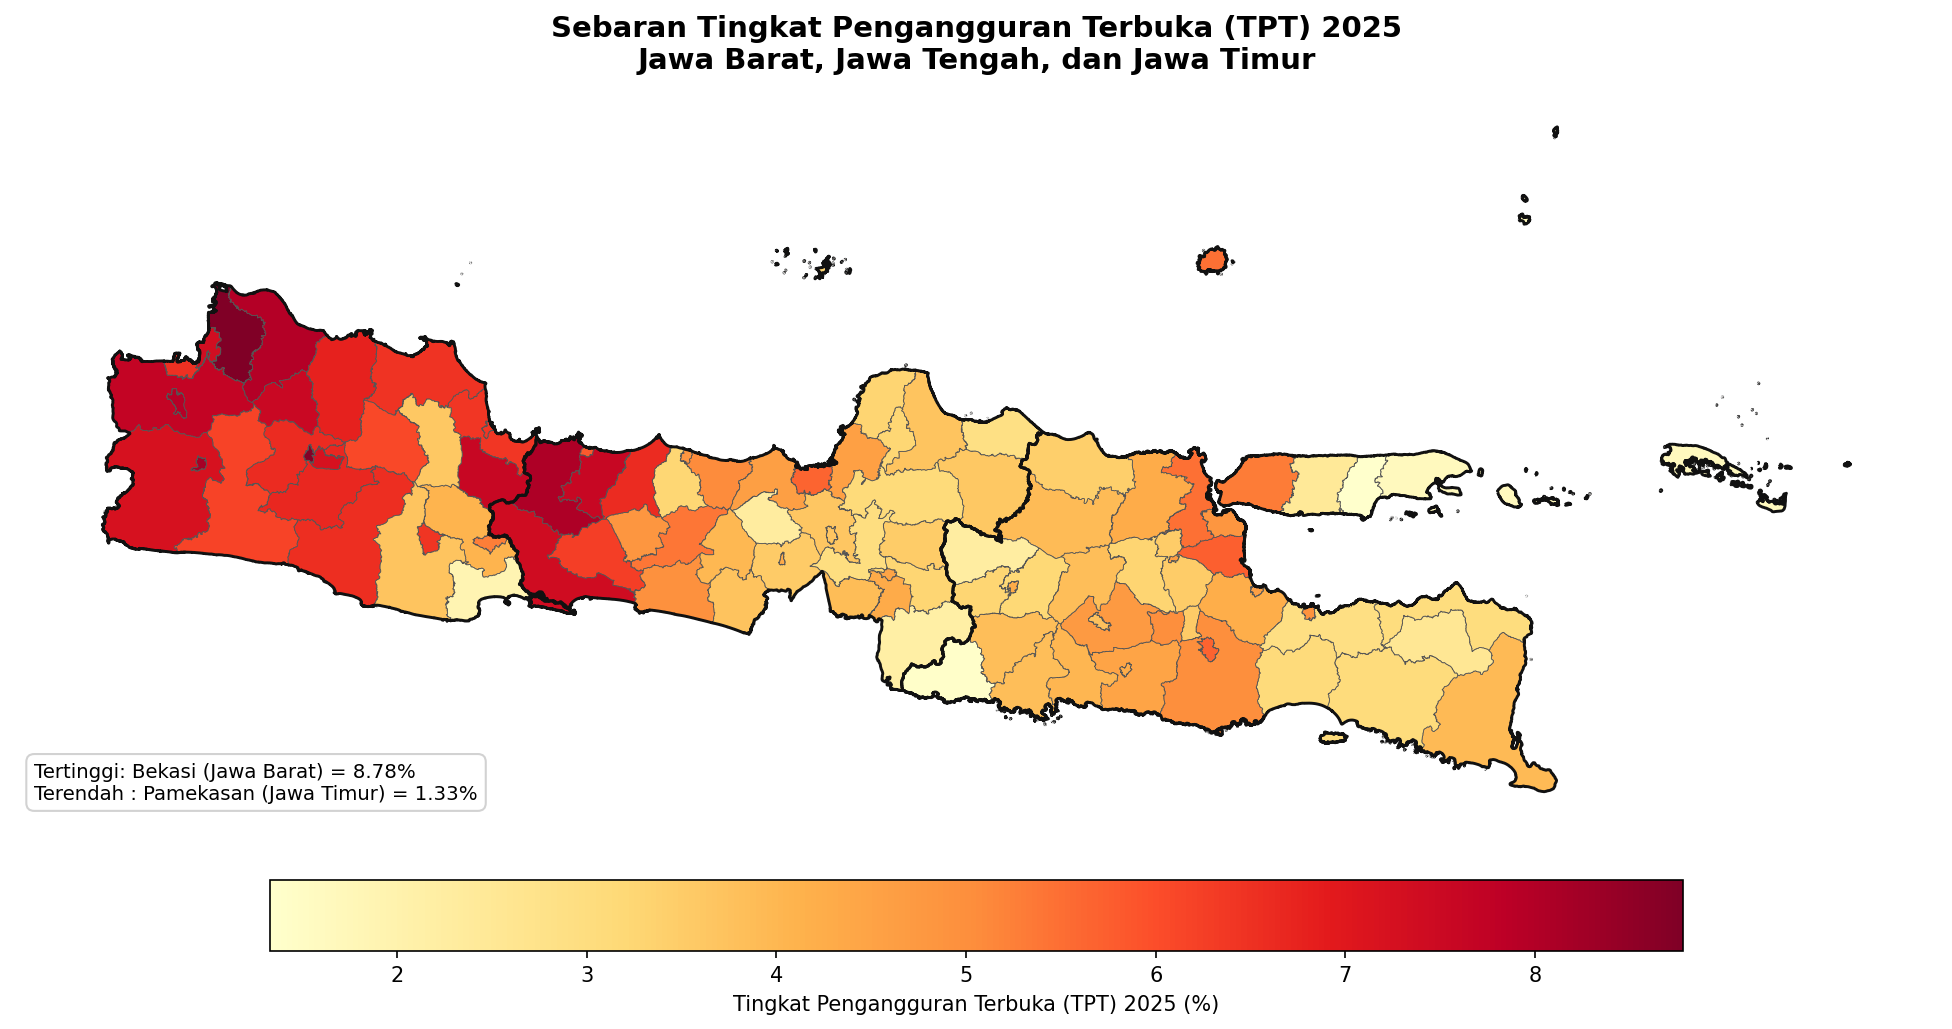

In [6]:
# Peta Sebaran (Choropleth Heatmap) TPT 2025 di Jawa Barat, Jawa Tengah, dan Jawa Timur
fig, ax = plt.subplots(figsize=(16, 7), dpi=150)

vmin = gdf_merged['TPT_2025'].min()
vmax = gdf_merged['TPT_2025'].max()

gdf_merged.plot(
    column='TPT_2025',
    cmap='YlOrRd',
    linewidth=0.4,
    edgecolor='#555555',
    vmin=vmin,
    vmax=vmax,
    legend=True,
    legend_kwds={
        'label': 'Tingkat Pengangguran Terbuka (TPT) 2025 (%)',
        'orientation': 'horizontal',
        'shrink': 0.6,
        'pad': 0.06
    },
    ax=ax
)

# Tambahkan garis batas provinsi yang lebih tegas
prov_boundary = gdf_merged.dissolve(by='Provinsi')
prov_boundary.boundary.plot(ax=ax, color='#111111', linewidth=1.4)

# Catatan wilayah tertinggi dan terendah
top_row = gdf_merged.loc[gdf_merged['TPT_2025'].idxmax()]
low_row = gdf_merged.loc[gdf_merged['TPT_2025'].idxmin()]
info_text = (
    f"Tertinggi: {top_row['Kabupaten_Kota']} ({top_row['Provinsi']}) = {top_row['TPT_2025']:.2f}%\n"
    f"Terendah : {low_row['Kabupaten_Kota']} ({low_row['Provinsi']}) = {low_row['TPT_2025']:.2f}%"
)
ax.text(
    0.01, 0.03, info_text, transform=ax.transAxes,
    fontsize=9.5, verticalalignment='bottom',
    bbox=dict(boxstyle='round,pad=0.4', facecolor='white', alpha=0.88, edgecolor='#cccccc')
)

ax.set_title('Sebaran Tingkat Pengangguran Terbuka (TPT) 2025\nJawa Barat, Jawa Tengah, dan Jawa Timur', fontsize=14, fontweight='bold', pad=12)
ax.set_axis_off()
plt.tight_layout()
plt.show()

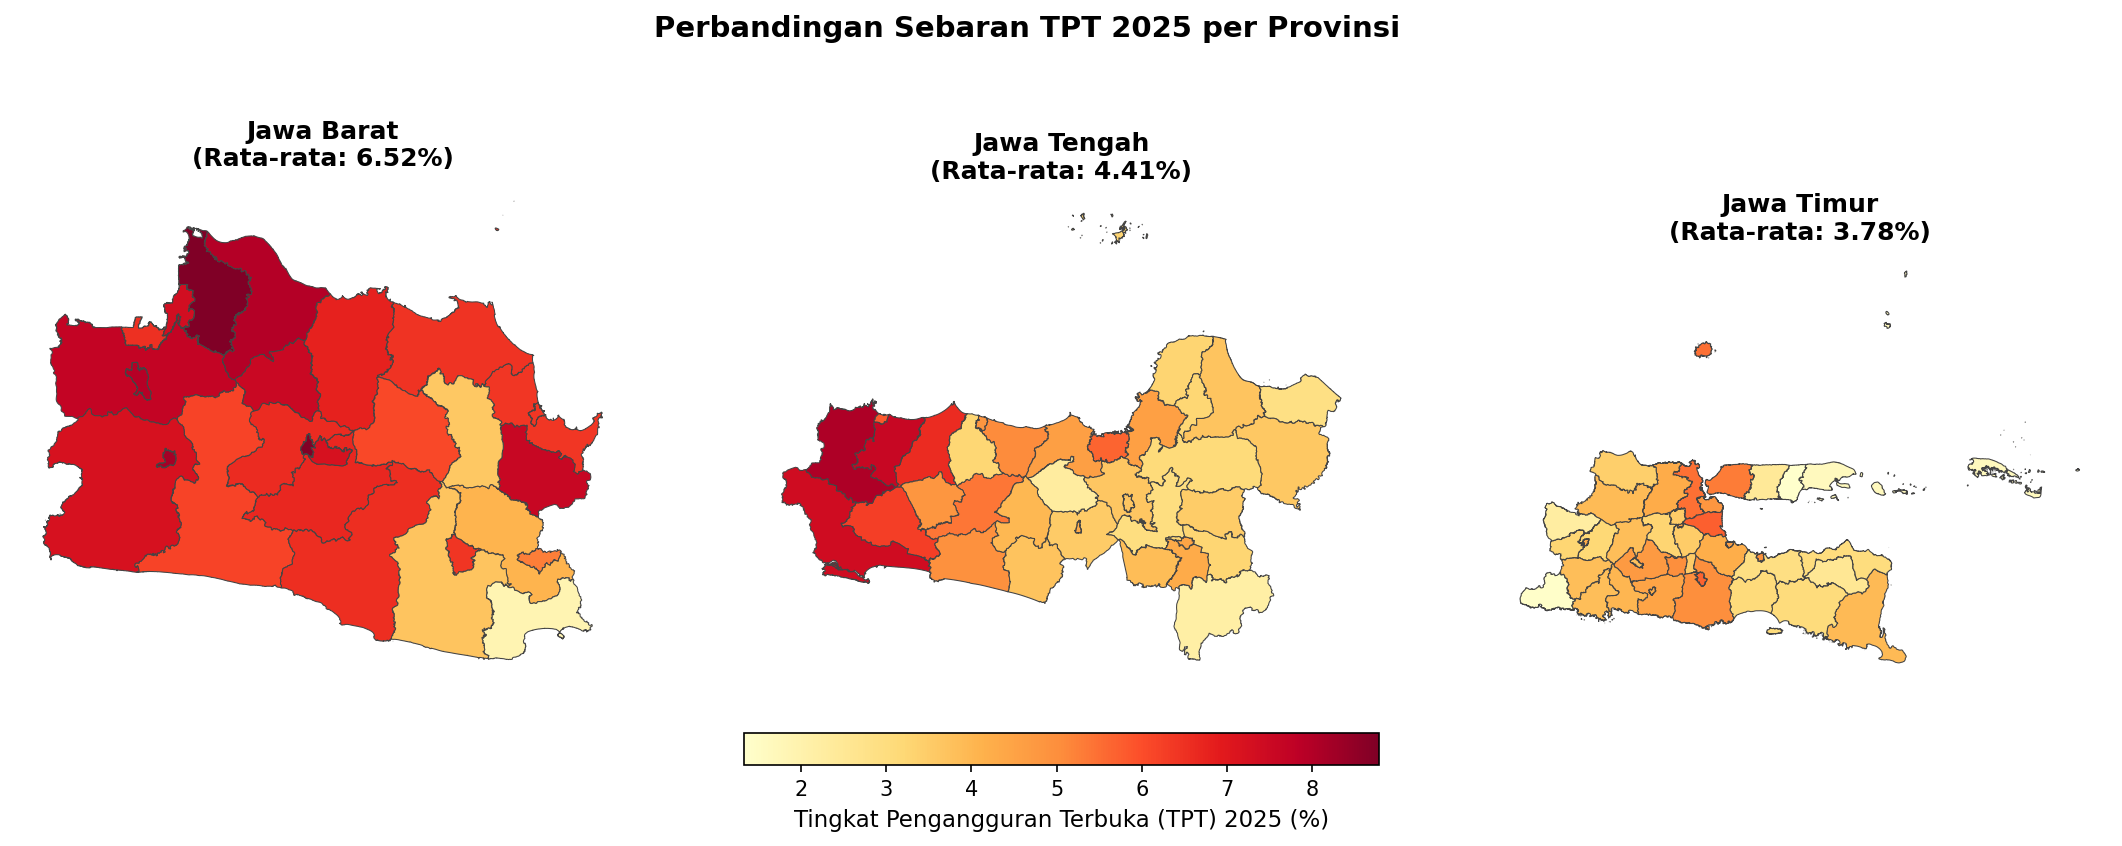

In [7]:
# Peta Sebaran TPT 2025 per Provinsi 
provinsi_list = ['Jawa Barat', 'Jawa Tengah', 'Jawa Timur']
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=150)

for ax, prov in zip(axes, provinsi_list):
    subset = gdf_merged[gdf_merged['Provinsi'] == prov]
    subset.plot(
        column='TPT_2025',
        cmap='YlOrRd',
        linewidth=0.5,
        edgecolor='#444444',
        vmin=vmin,
        vmax=vmax,
        ax=ax
    )
    ax.set_title(f'{prov}\n(Rata-rata: {subset["TPT_2025"].mean():.2f}%)', fontsize=12, fontweight='bold')
    ax.set_axis_off()

sm = plt.cm.ScalarMappable(cmap='YlOrRd', norm=plt.Normalize(vmin=vmin, vmax=vmax))
sm._A = []
cbar = fig.colorbar(sm, ax=axes, orientation='horizontal', fraction=0.05, pad=0.08, shrink=0.5)
cbar.set_label('Tingkat Pengangguran Terbuka (TPT) 2025 (%)', fontsize=11)

fig.suptitle('Perbandingan Sebaran TPT 2025 per Provinsi', fontsize=14, fontweight='bold', y=1.02)
plt.show()

Dari heatmap diatas, bisa dilihat kalau sebaran tingkat pengangguran terbuka tertinggi didominasi oleh  provinsi jawa barat, kedua jawa tengah dan terendah di jawa timur.  Secara khusus kota dengan tingkat pengangguran tertinggi berada di kota bekasi dengan tinngkat pengangguran terbuka hingga 8.78% dan terendah berada di kota pemekasan jawa timur hanya dengan 1.33%. Hal ini mengindikasikan kurangnya penanganan masalah pengangguran secara merata. Hal ini diperkuat oleh tingkat angkatan kerja dengan rincian berikut

| Provinsi | Jumlah Angkatan Kerja | Penduduk Bekerja | Jumlah Penganggur | Tingkat Pengangguran Terbuka (TPT) | Faktor Dominan yang Mempengaruhi |
| :--- | :--- | :--- | :--- | :--- | :--- |
| **Jawa Barat** | 26,29 juta *(est.)* | 24,51 juta | 1,78 juta *(est.)* | **6,77%** | Tingginya pasokan angkatan kerja di kawasan industri (seperti Bekasi & Karawang) serta tingginya TPT lulusan SMK. |
| **Jawa Tengah** | 22,34 juta | 21,30 juta | 1,04 juta | **4,66%** | Pertumbuhan angkatan kerja dan TPAK yang meningkat signifikan, sementara penyerapan sektor formal masih terbatas. |
| **Jawa Timur** | 24,76 juta | 23,80 juta | 0,96 juta | **3,88%** | Pertumbuhan ekonomi (5,22% y-on-y) yang ditopang industri pengolahan dan perdagangan serta realisasi investasi padat karya. |


Histogram dan boxplot


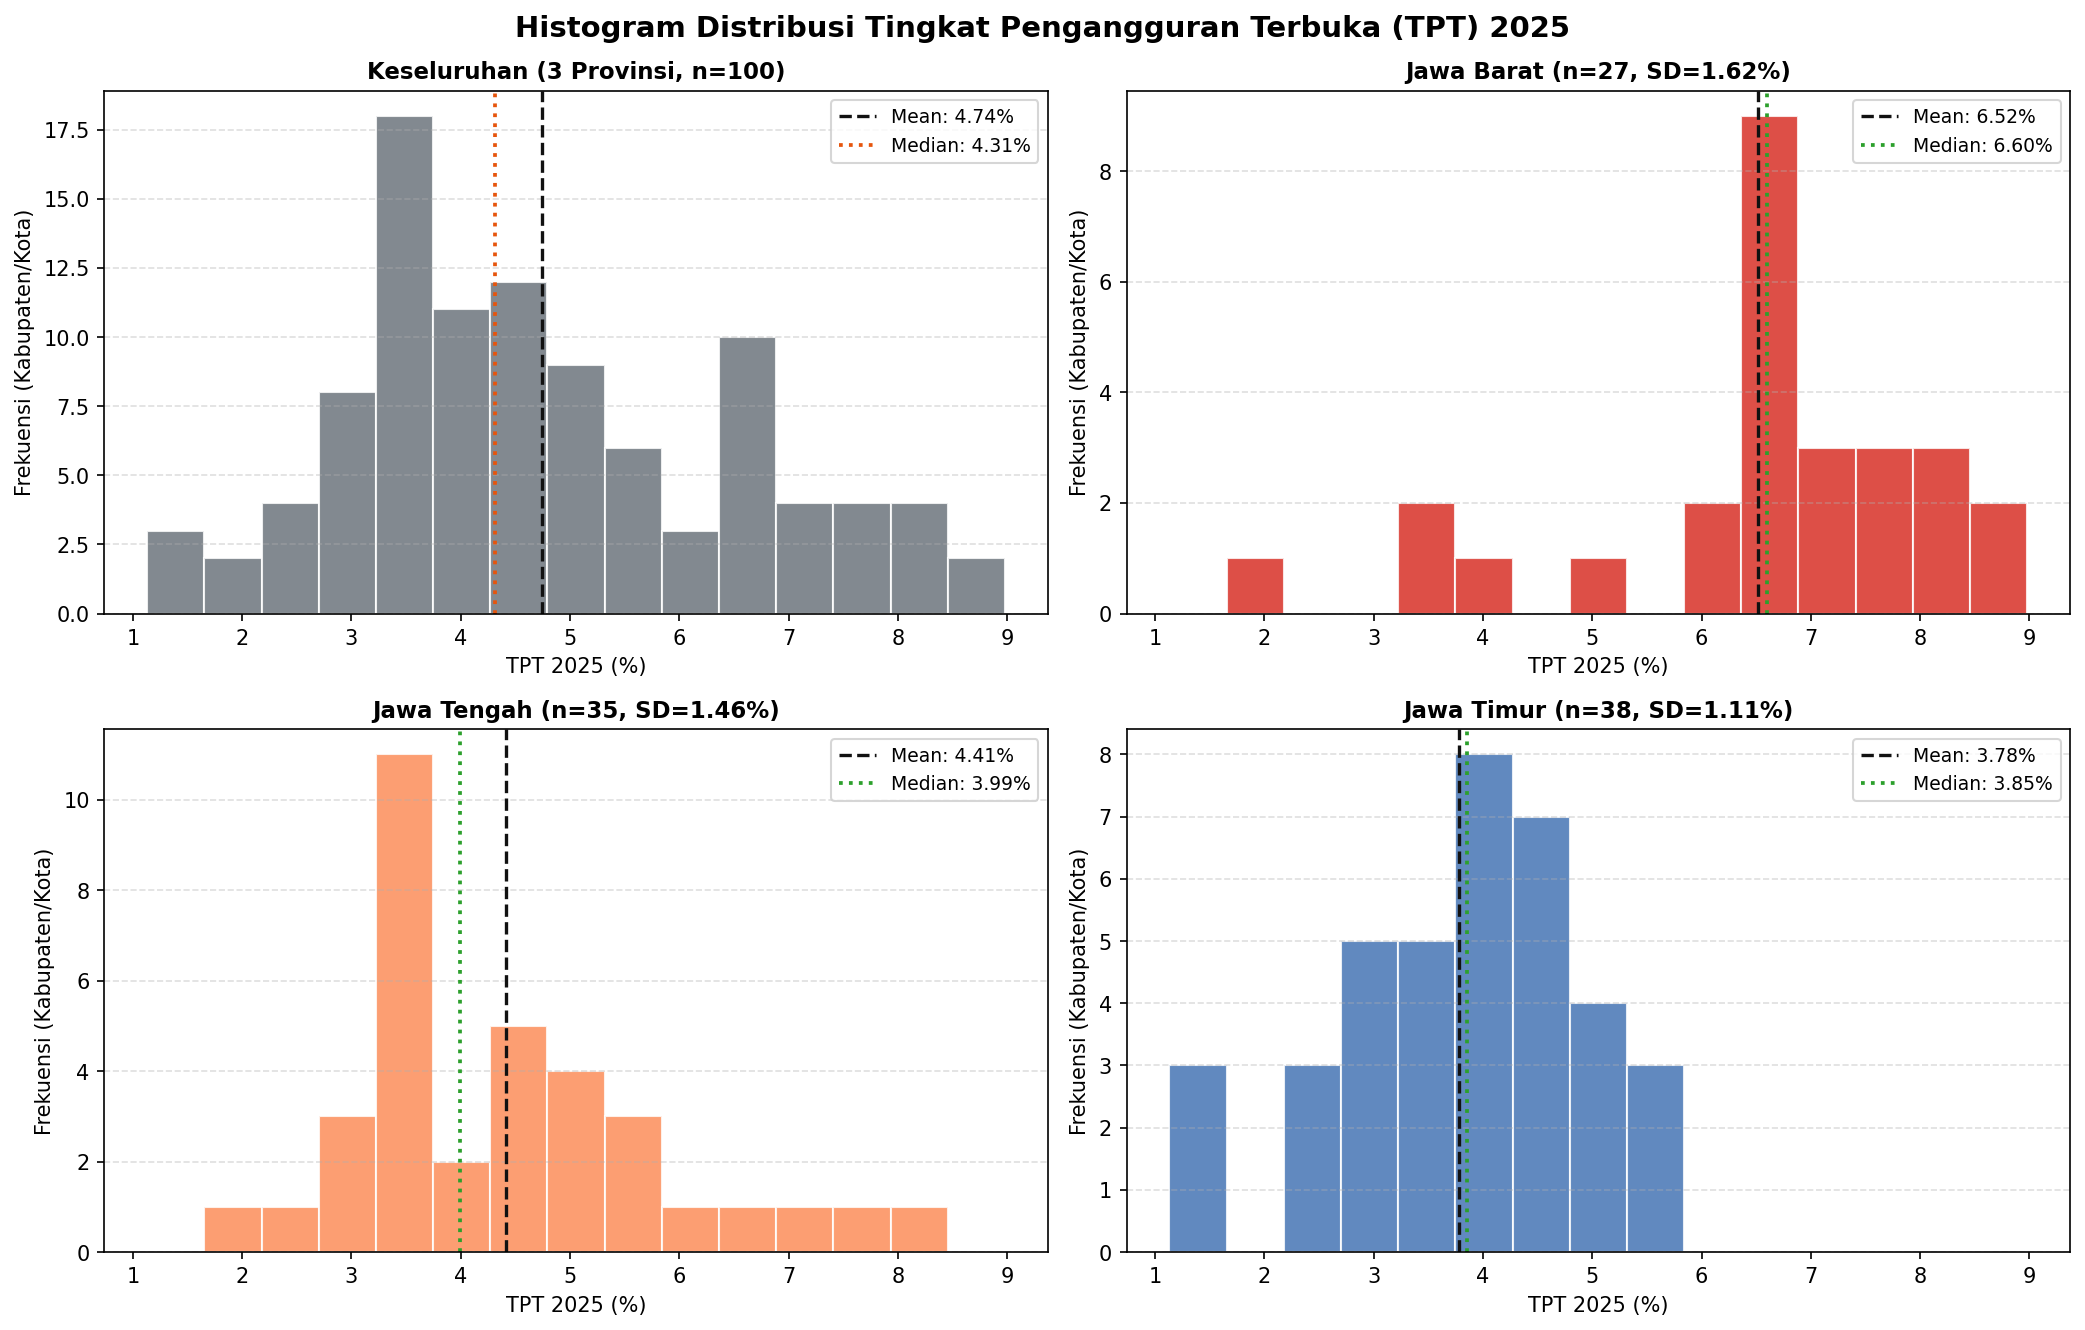

In [8]:
# Histogram Distribusi TPT 2025 (Keseluruhan dan per Provinsi)
provinsi_list = ['Jawa Barat', 'Jawa Tengah', 'Jawa Timur']
colors = {'Jawa Barat': '#d73027', 'Jawa Tengah': '#fc8d59', 'Jawa Timur': '#4575b4'}

fig, axes = plt.subplots(2, 2, figsize=(14, 9), dpi=150)

# Histogram keseluruhan
ax_all = axes[0, 0]
data_all = df_tpt['TPT_2025']
bins = np.linspace(data_all.min() - 0.2, data_all.max() + 0.2, 16)
ax_all.hist(data_all, bins=bins, color='#6c757d', edgecolor='white', alpha=0.85)
ax_all.axvline(data_all.mean(), color='#111111', linestyle='--', linewidth=1.6, label=f'Mean: {data_all.mean():.2f}%')
ax_all.axvline(data_all.median(), color='#e6550d', linestyle=':', linewidth=1.8, label=f'Median: {data_all.median():.2f}%')
ax_all.set_title(f'Keseluruhan (3 Provinsi, n={len(data_all)})', fontsize=11, fontweight='bold')
ax_all.set_xlabel('TPT 2025 (%)')
ax_all.set_ylabel('Frekuensi (Kabupaten/Kota)')
ax_all.legend(fontsize=9)
ax_all.grid(axis='y', linestyle='--', alpha=0.4)

# Histogram per provinsi
prov_axes = [axes[0, 1], axes[1, 0], axes[1, 1]]
for ax, prov in zip(prov_axes, provinsi_list):
    sub = df_tpt[df_tpt['Provinsi'] == prov]['TPT_2025']
    ax.hist(sub, bins=bins, color=colors[prov], edgecolor='white', alpha=0.85)
    ax.axvline(sub.mean(), color='#111111', linestyle='--', linewidth=1.6, label=f'Mean: {sub.mean():.2f}%')
    ax.axvline(sub.median(), color='#2ca02c', linestyle=':', linewidth=1.8, label=f'Median: {sub.median():.2f}%')
    ax.set_title(f'{prov} (n={len(sub)}, SD={sub.std():.2f}%)', fontsize=11, fontweight='bold')
    ax.set_xlabel('TPT 2025 (%)')
    ax.set_ylabel('Frekuensi (Kabupaten/Kota)')
    ax.legend(fontsize=9)
    ax.grid(axis='y', linestyle='--', alpha=0.4)

fig.suptitle('Histogram Distribusi Tingkat Pengangguran Terbuka (TPT) 2025', fontsize=14, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

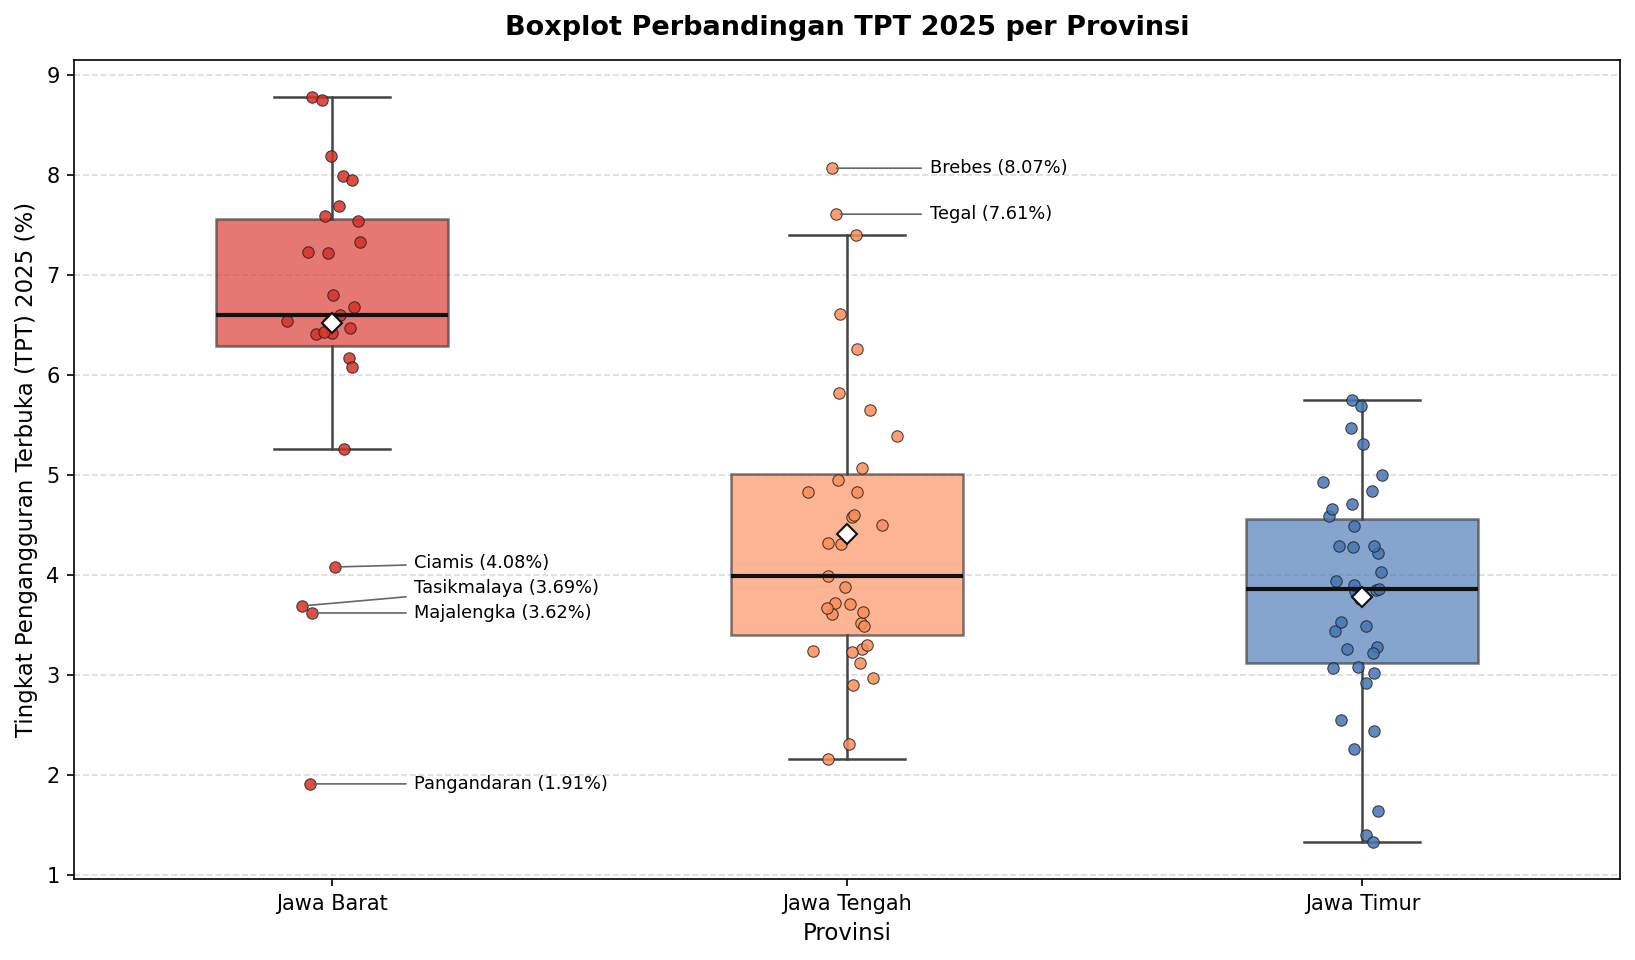

              n  mean  median   std    q1    q3   min   max   iqr
Provinsi                                                         
Jawa Barat   27  6.52    6.60  1.62  6.29  7.56  1.91  8.78  1.27
Jawa Tengah  35  4.41    3.99  1.46  3.40  5.01  2.16  8.07  1.61
Jawa Timur   38  3.78    3.86  1.11  3.12  4.56  1.33  5.75  1.44


In [13]:
# Boxplot Perbandingan TPT 2025 per Provinsi
fig, ax = plt.subplots(figsize=(11, 6.5), dpi=150)

data_groups = [df_tpt[df_tpt['Provinsi'] == p]['TPT_2025'].values for p in provinsi_list]
bp = ax.boxplot(
    data_groups,
    tick_labels=provinsi_list,
    patch_artist=True,
    showmeans=True,
    showfliers=False,
    meanprops=dict(marker='D', markerfacecolor='white', markeredgecolor='#111111', markersize=7, zorder=4),
    medianprops=dict(color='#111111', linewidth=2, zorder=4),
    whiskerprops=dict(color='#444444', linewidth=1.2),
    capprops=dict(color='#444444', linewidth=1.2),
    widths=0.45
)

for patch, prov in zip(bp['boxes'], provinsi_list):
    patch.set_facecolor(colors[prov])
    patch.set_alpha(0.65)
    patch.set_edgecolor('#333333')
    patch.set_linewidth(1.2)

# Tambahkan titik data (jitter) dan anotasi outlier tanpa tumpang tindih
rng = np.random.default_rng(42)
for i, prov in enumerate(provinsi_list, start=1):
    sub_df = df_tpt[df_tpt['Provinsi'] == prov].copy()
    sub_df['jitter_x'] = rng.normal(i, 0.045, size=len(sub_df))
    ax.scatter(
        sub_df['jitter_x'], sub_df['TPT_2025'],
        color=colors[prov], edgecolor='#222222', linewidth=0.5,
        s=30, alpha=0.85, zorder=3
    )

    q1, q3 = np.percentile(sub_df['TPT_2025'], [25, 75])
    iqr = q3 - q1
    outliers = sub_df[
        (sub_df['TPT_2025'] < q1 - 1.5 * iqr) |
        (sub_df['TPT_2025'] > q3 + 1.5 * iqr)
    ].sort_values('TPT_2025')

    # Atur jarak vertikal minimum antar label outlier agar tidak bertumpuk
    last_y = -np.inf
    for _, row in outliers.iterrows():
        text_y = max(row['TPT_2025'], last_y + 0.25)
        last_y = text_y
        ax.annotate(
            f"{row['Kabupaten_Kota']} ({row['TPT_2025']:.2f}%)",
            xy=(row['jitter_x'], row['TPT_2025']),
            xytext=(i + 0.16, text_y),
            fontsize=8.5,
            va='center',
            arrowprops=dict(arrowstyle='-', color='#666666', lw=0.8)
        )

ax.set_title('Boxplot Perbandingan TPT 2025 per Provinsi', fontsize=13, fontweight='bold', pad=12)
ax.set_ylabel('Tingkat Pengangguran Terbuka (TPT) 2025 (%)', fontsize=11)
ax.set_xlabel('Provinsi', fontsize=11)
ax.grid(axis='y', linestyle='--', alpha=0.45)

plt.tight_layout()
plt.show()

# Ringkasan statistik deskriptif per provinsi
summary_stats = df_tpt.groupby('Provinsi')['TPT_2025'].agg(
    n='count',
    mean='mean',
    median='median',
    std='std',
    q1=lambda s: s.quantile(0.25),
    q3=lambda s: s.quantile(0.75),
    min='min',
    max='max'
).round(2)
summary_stats['iqr'] = (summary_stats['q3'] - summary_stats['q1']).round(2)
print(summary_stats)


**2. UJI ASUMSI ANOVA**

=== Hasil Uji Normalitas Residual (Shapiro-Wilk) ===
n           : 100
Statistik W : 0.9883
p-value     : 0.5271
Kesimpulan  : Normal (p >= 0.05)


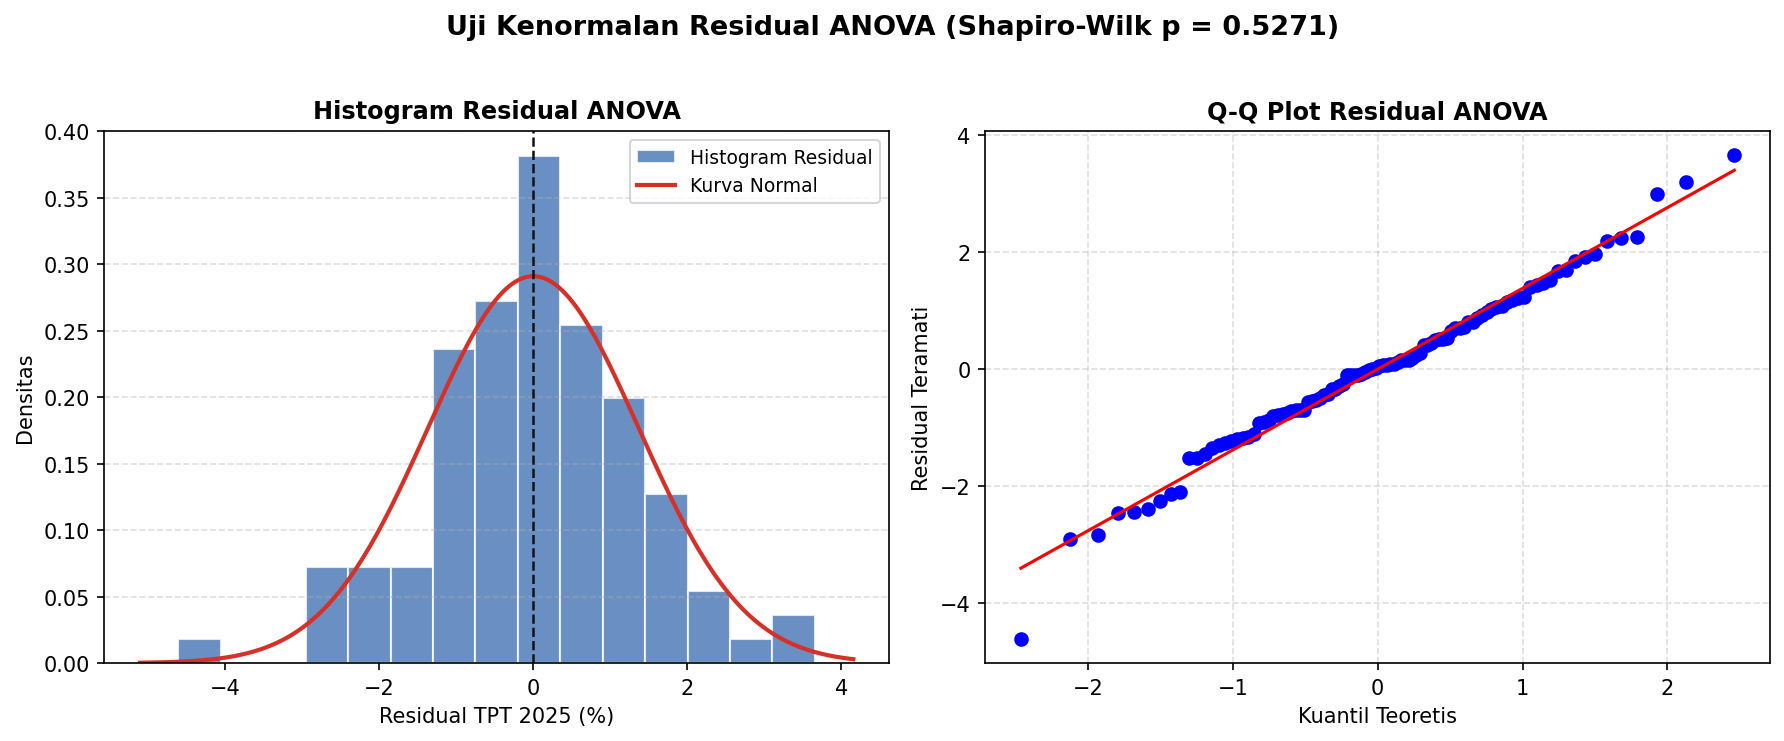

In [18]:
# 1. Uji Kenormalan Residual ANOVA (Shapiro-Wilk Test, Histogram Residual, & Q-Q Plot)
from scipy import stats

alpha = 0.05

# Hitung residual ANOVA (nilai observasi - rata-rata kelompok provinsi)
df_tpt['residual'] = df_tpt['TPT_2025'] - df_tpt.groupby('Provinsi')['TPT_2025'].transform('mean')
residuals = df_tpt['residual'].values

# Uji Shapiro-Wilk pada residual
stat_res, p_res = stats.shapiro(residuals)
print('=== Hasil Uji Normalitas Residual (Shapiro-Wilk) ===')
print(f'n           : {len(residuals)}')
print(f'Statistik W : {stat_res:.4f}')
print(f'p-value     : {p_res:.4f}')
print(f'Kesimpulan  : {"Normal (p >= 0.05)" if p_res >= alpha else "Tidak Normal (p < 0.05)"}')

# Visualisasi Histogram Residual dan Q-Q Plot Residual
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), dpi=150)

# Panel 1: Histogram Residual + Kurva Normal Teoretis
ax_hist = axes[0]
ax_hist.hist(residuals, bins=15, density=True, color='#4575b4', edgecolor='white', alpha=0.8, label='Histogram Residual')
x_grid = np.linspace(residuals.min() - 0.5, residuals.max() + 0.5, 200)
ax_hist.plot(x_grid, stats.norm.pdf(x_grid, loc=residuals.mean(), scale=residuals.std(ddof=1)),
             color='#d73027', linewidth=2, label='Kurva Normal')
ax_hist.axvline(0, color='#111111', linestyle='--', linewidth=1.2)
ax_hist.set_title('Histogram Residual ANOVA', fontsize=11.5, fontweight='bold')
ax_hist.set_xlabel('Residual TPT 2025 (%)')
ax_hist.set_ylabel('Densitas')
ax_hist.legend(fontsize=9)
ax_hist.grid(axis='y', linestyle='--', alpha=0.4)

# Panel 2: Q-Q Plot Residual
ax_qq = axes[1]
stats.probplot(residuals, dist='norm', plot=ax_qq)
ax_qq.set_title('Q-Q Plot Residual ANOVA', fontsize=11.5, fontweight='bold')
ax_qq.set_xlabel('Kuantil Teoretis')
ax_qq.set_ylabel('Residual Teramati')
ax_qq.grid(linestyle='--', alpha=0.4)

fig.suptitle(f'Uji Kenormalan Residual ANOVA (Shapiro-Wilk p = {p_res:.4f})', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

In [19]:
# 2. Uji Homogenitas Varians / Heterogenitas (Levene's Test & Bartlett's Test)
provinsi_list = ['Jawa Barat', 'Jawa Tengah', 'Jawa Timur']
groups = [df_tpt[df_tpt['Provinsi'] == p]['TPT_2025'].values for p in provinsi_list]

# Varians masing-masing kelompok
var_summary = pd.DataFrame({
    'Provinsi': provinsi_list,
    'n': [len(g) for g in groups],
    'Varians': [round(np.var(g, ddof=1), 4) for g in groups],
    'Std Deviasi': [round(np.std(g, ddof=1), 4) for g in groups]
})
print('=== Ringkasan Varians per Provinsi ===')
print(var_summary.to_string(index=False))

# Levene's test & Bartlett's test
lev_stat, lev_p = stats.levene(*groups, center='median')
bart_stat, bart_p = stats.bartlett(*groups)

hasil_homogenitas = pd.DataFrame([
    {
        'Metode Uji': "Levene's Test (median)",
        'Statistik': round(lev_stat, 4),
        'p-value': round(lev_p, 4),
        'Kesimpulan (alpha=0.05)': 'Homogen (Varians sama)' if lev_p >= alpha else 'Heterogen (Varians berbeda)'
    },
    {
        'Metode Uji': "Bartlett's Test",
        'Statistik': round(bart_stat, 4),
        'p-value': round(bart_p, 4),
        'Kesimpulan (alpha=0.05)': 'Homogen (Varians sama)' if bart_p >= alpha else 'Heterogen (Varians berbeda)'
    }
])

print('\n=== Hasil Uji Homogenitas Varians ===')
print(hasil_homogenitas.to_string(index=False))

if p_res >= alpha and lev_p >= alpha:
    print('\nKesimpulan Asumsi: Residual berdistribusi normal dan varians antar kelompok homogen -> Asumsi ANOVA terpenuhi, lanjutkan dengan One-Way ANOVA.')
elif lev_p < alpha:
    print('\nKesimpulan Asumsi: Varians antar kelompok heterogen (p < 0.05) -> gunakan Welch ANOVA.')
else:
    print('\nKesimpulan Asumsi: Residual tidak berdistribusi normal (p < 0.05) -> pertimbangkan Kruskal-Wallis.')

=== Ringkasan Varians per Provinsi ===
   Provinsi  n  Varians  Std Deviasi
 Jawa Barat 27   2.6135       1.6166
Jawa Tengah 35   2.1223       1.4568
 Jawa Timur 38   1.2382       1.1128

=== Hasil Uji Homogenitas Varians ===
            Metode Uji  Statistik  p-value Kesimpulan (alpha=0.05)
Levene's Test (median)     0.8312   0.4386  Homogen (Varians sama)
       Bartlett's Test     4.5770   0.1014  Homogen (Varians sama)

Kesimpulan Asumsi: Residual berdistribusi normal dan varians antar kelompok homogen -> Asumsi ANOVA terpenuhi, lanjutkan dengan One-Way ANOVA.


Hasil uji asumsi di atas mengindikasikan kita bisa menggunakan ANOVA klasik (one way anova). 

**3. ANOVA**

In [ ]:
# Perhitungan Komponen & Tabel One-Way ANOVA secara Manual + Verifikasi SciPy
from scipy import stats

provinsi_list = ['Jawa Barat', 'Jawa Tengah', 'Jawa Timur']
alpha = 0.05

# Data per kelompok
groups = [df_tpt[df_tpt['Provinsi'] == p]['TPT_2025'].values for p in provinsi_list]
k = len(groups)
n_i = [len(g) for g in groups]
N = sum(n_i)

# Total per kelompok dan Grand Total
sum_i = [np.sum(g) for g in groups]
mean_i = [np.mean(g) for g in groups]
grand_total = np.sum(df_tpt['TPT_2025'].values)
sum_sq_all = np.sum(df_tpt['TPT_2025'].values ** 2)

# 1. Faktor Koreksi (FK)
FK = (grand_total ** 2) / N

# 2. Jumlah Kuadrat (JK / Sum of Squares)
JKT = sum_sq_all - FK                                          # Jumlah Kuadrat Total
JKP = sum((s ** 2) / n for s, n in zip(sum_i, n_i)) - FK       # Jumlah Kuadrat Perlakuan (Antar Kelompok)
JKG = JKT - JKP                                                # Jumlah Kuadrat Galat (Dalam Kelompok)

# 3. Derajat Bebas (db / df)
db_perlakuan = k - 1
db_galat = N - k
db_total = N - 1

# 4. Kuadrat Tengah (KT / Mean Square)
KTP = JKP / db_perlakuan
KTG = JKG / db_galat

# 5. F-hitung, F-tabel, dan p-value
F_hitung = KTP / KTG
F_tabel = stats.f.ppf(1 - alpha, db_perlakuan, db_galat)
p_value = stats.f.sf(F_hitung, db_perlakuan, db_galat)

print('=== Ringkasan per Kelompok ===')
ringkasan_kel = pd.DataFrame({
    'Provinsi': provinsi_list,
    'n_i': n_i,
    'Jumlah (Sum Y_i)': [round(s, 4) for s in sum_i],
    'Rata-rata (Mean)': [round(m, 4) for m in mean_i]
})
print(ringkasan_kel.to_string(index=False))

print('\n=== Komponen Perhitungan ANOVA ===')
print(f'N (Total Data)       = {N}')
print(f'k (Jumlah Kelompok)  = {k}')
print(f'Grand Total (Sum Y)  = {grand_total:.4f}')
print(f'Sum(Y^2)             = {sum_sq_all:.4f}')
print(f'FK (Faktor Koreksi)  = {FK:.4f}')
print(f'JKT (JK Total)       = {JKT:.4f}')
print(f'JKP (JK Perlakuan)   = {JKP:.4f}')
print(f'JKG (JK Galat)       = {JKG:.4f}')
print(f'KTP (KT Perlakuan)   = {KTP:.4f}')
print(f'KTG (KT Galat)       = {KTG:.4f}')

# Tabel ANOVA
tabel_anova = pd.DataFrame([
    {
        'Sumber Keragaman': 'Perlakuan (Antar Provinsi)',
        'db': db_perlakuan,
        'JK': round(JKP, 4),
        'KT': round(KTP, 4),
        'F_hitung': round(F_hitung, 4),
        'F_tabel (0.05)': round(F_tabel, 4),
        'p-value': f'{p_value:.4e}'
    },
    {
        'Sumber Keragaman': 'Galat (Dalam Provinsi)',
        'db': db_galat,
        'JK': round(JKG, 4),
        'KT': round(KTG, 4),
        'F_hitung': '-',
        'F_tabel (0.05)': '-',
        'p-value': '-'
    },
    {
        'Sumber Keragaman': 'Total',
        'db': db_total,
        'JK': round(JKT, 4),
        'KT': '-',
        'F_hitung': '-',
        'F_tabel (0.05)': '-',
        'p-value': '-'
    }
])

print('\n=== Tabel One-Way ANOVA ===')
print(tabel_anova.to_string(index=False))

# Verifikasi dengan SciPy f_oneway
f_scipy, p_scipy = stats.f_oneway(*groups)
print(f'\nVerifikasi SciPy f_oneway -> F = {f_scipy:.4f}, p-value = {p_scipy:.4e}')

# Keputusan Uji Hipotesis
if F_hitung > F_tabel and p_value < alpha:
    print('\nKeputusan: Tolak H0 (F_hitung > F_tabel dan p-value < 0.05).')
    print('Kesimpulan: Terdapat perbedaan rata-rata TPT 2025 yang signifikan antara minimal dua provinsi di Jawa Barat, Jawa Tengah, dan Jawa Timur.')
else:
    print('\nKeputusan: Gagal Tolak H0.')
    print('Kesimpulan: Tidak terdapat perbedaan rata-rata TPT 2025 yang signifikan antar provinsi.')

Hasil menunjukkan p value yang diperoleh  kurang daarai taraf nyata 5%, sehingga kita reject pernyataan bahwa rataan tiap kelompok sama, atau dengan kata lain rataan tingkat pengangguran terbuka tiap provinsi berbeda signfikan. Hal ini selaras dengan dugaan awal di tahap eksplorasi data